[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/eigenvalues-and-eigenvectors/notebook.ipynb)

# Eigenvalues and Eigenvectors: hands-on

This notebook goes with the [topic README](README.md). You will watch a matrix act on a circle of vectors, compute eigenvalues and eigenvectors, diagonalize a matrix and use it for powers, meet a matrix that cannot be diagonalized, check the spectral theorem for a symmetric matrix, test for positive definiteness, write the power method, and see eigenvectors at work in a covariance ellipse, a tiny PageRank, and gradient descent on a quadratic. All data are synthetic. It uses NumPy, Matplotlib, `scipy.linalg`, and SymPy, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so we compare with `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=4, suppress=True)

## 1. A matrix acts on a circle of vectors

Take the matrix $A$ below and apply it to 24 unit vectors around the circle. Most vectors **turn** as well as stretch. A few special directions, the **eigenvectors**, keep their direction: the matrix only scales them by the eigenvalue $\lambda$.

In [2]:
A = np.array([[4.0, 1.0],
              [2.0, 3.0]])

eigenvalues, eigenvectors = np.linalg.eig(A)        # columns of `eigenvectors` are the eigenvectors
print("eigenvalues :", eigenvalues)
print("eigenvectors (columns):\n", eigenvectors)
for lam, v in zip(eigenvalues, eigenvectors.T):
    print(f"lambda = {lam:.0f}:  A v = {A @ v}   lambda v = {lam * v}   equal: {np.allclose(A @ v, lam * v)}")

eigenvalues : [5. 2.]
eigenvectors (columns):
 [[ 0.7071 -0.4472]
 [ 0.7071  0.8944]]
lambda = 5:  A v = [3.5355 3.5355]   lambda v = [3.5355 3.5355]   equal: True
lambda = 2:  A v = [-0.8944  1.7889]   lambda v = [-0.8944  1.7889]   equal: True


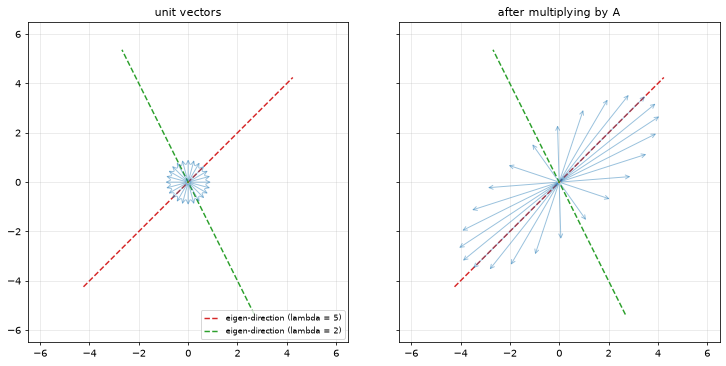

In [3]:
angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
circle = np.vstack([np.cos(angles), np.sin(angles)])        # 24 unit vectors as columns
image = A @ circle

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, pts, title in [(axes[0], circle, "unit vectors"), (axes[1], image, "after multiplying by A")]:
    for k in range(pts.shape[1]):
        ax.annotate("", xy=pts[:, k], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", alpha=0.45, lw=1))
    for lam, v, color in zip(eigenvalues, eigenvectors.T, ["C3", "C2"]):
        ax.plot([-6 * v[0], 6 * v[0]], [-6 * v[1], 6 * v[1]], color=color, ls="--", lw=1.5,
                label=f"eigen-direction (lambda = {lam:.0f})")
    ax.set_xlim(-6.5, 6.5); ax.set_ylim(-6.5, 6.5); ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.set_title(title)
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

Compare the two panels. Almost every blue arrow ends up pointing somewhere new. The arrows that lie along a dashed line stay on that line: the ones on the red line are multiplied by 5 and the ones on the green line by 2.

## 2. The characteristic equation by hand and by machine

Eigenvalues are the roots of $\det(A - \lambda I) = 0$. SymPy does the algebra exactly. We also check that the eigenvalues add up to the trace and multiply to the determinant.

In [4]:
lam = sp.symbols("lambda")
A_sym = sp.Matrix([[4, 1], [2, 3]])
char_poly = (A_sym - lam * sp.eye(2)).det()
print("det(A - lambda I) =", sp.expand(char_poly), "=", sp.factor(char_poly))
print("roots:", sp.solve(char_poly, lam))

print("\nsum of eigenvalues     =", eigenvalues.sum(), "| trace  =", np.trace(A))
print("product of eigenvalues =", round(eigenvalues.prod(), 10), "| det    =", round(np.linalg.det(A), 10))

B = np.array([[2.0, 1.0, 0.0],
              [1.0, 3.0, 1.0],
              [0.0, 1.0, 2.0]])
print("\n3 x 3 example, eigenvalues:", np.linalg.eigvalsh(B), "| trace =", np.trace(B), "| det =", round(np.linalg.det(B), 10))

T = np.array([[2.0, 1.0, 4.0], [0.0, 3.0, 5.0], [0.0, 0.0, 6.0]])
print("triangular matrix: eigenvalues", np.sort(np.linalg.eigvals(T)), "= its diagonal")

det(A - lambda I) = lambda**2 - 7*lambda + 10 = (lambda - 5)*(lambda - 2)
roots: [2, 5]

sum of eigenvalues     = 7.0 | trace  = 7.0
product of eigenvalues = 10.0 | det    = 10.0

3 x 3 example, eigenvalues: [1. 2. 4.] | trace = 7.0 | det = 8.0
triangular matrix: eigenvalues [2. 3. 6.] = its diagonal


## 3. Eigenvectors are the nullspace of $A - \lambda I$

For each eigenvalue, the eigenvectors are exactly the nonzero vectors in the nullspace of $A - \lambda I$. That connects this topic to the nullspace from earlier.

In [5]:
for lam_value in (5.0, 2.0):
    N = sla.null_space(A - lam_value * np.eye(2))
    v = N[:, 0] / N[0, 0]                          # scale so the first entry is 1
    print(f"lambda = {lam_value:.0f}: nullspace of A - lambda I is spanned by {v}  (dimension {N.shape[1]})")

# singular matrices have eigenvalue 0 (a nontrivial nullspace)
S0 = np.array([[1.0, 2.0], [2.0, 4.0]])
print("\nsingular matrix eigenvalues:", np.linalg.eigvalsh(S0), "| det =", round(np.linalg.det(S0), 10))

# eigenvalues of related matrices
print("\nA^3 eigenvalues      :", np.sort(np.linalg.eigvals(np.linalg.matrix_power(A, 3))), "(cubes of 2 and 5)")
print("inverse eigenvalues  :", np.sort(np.linalg.eigvals(np.linalg.inv(A))), "(reciprocals)")
print("A + 10 I eigenvalues :", np.sort(np.linalg.eigvals(A + 10 * np.eye(2))), "(shifted by 10)")

lambda = 5: nullspace of A - lambda I is spanned by [1. 1.]  (dimension 1)
lambda = 2: nullspace of A - lambda I is spanned by [ 1. -2.]  (dimension 1)

singular matrix eigenvalues: [0. 5.] | det = 0.0

A^3 eigenvalues      : [  8. 125.] (cubes of 2 and 5)
inverse eigenvalues  : [0.2 0.5] (reciprocals)
A + 10 I eigenvalues : [12. 15.] (shifted by 10)


## 4. A rotation has no real eigenvectors

A rotation by 90 degrees turns every vector, so no real direction stays put. The eigenvalues are complex: $\pm i$.

In [6]:
theta = np.pi / 2
Rot = np.array([[np.cos(theta), -np.sin(theta)],
                [np.sin(theta),  np.cos(theta)]])
w_rot, V_rot = np.linalg.eig(Rot)
print("eigenvalues of a 90-degree rotation:", w_rot)
print("their absolute values (a rotation keeps lengths):", np.abs(w_rot))

Rot30 = np.array([[np.cos(np.pi / 6), -np.sin(np.pi / 6)], [np.sin(np.pi / 6), np.cos(np.pi / 6)]])
w30 = np.linalg.eigvals(Rot30)
print("\n30-degree rotation:", w30, "| cos 30 =", round(np.cos(np.pi / 6), 4), ", sin 30 =", round(np.sin(np.pi / 6), 4))

eigenvalues of a 90-degree rotation: [0.+1.j 0.-1.j]
their absolute values (a rotation keeps lengths): [1. 1.]

30-degree rotation: [0.866+0.5j 0.866-0.5j] | cos 30 = 0.866 , sin 30 = 0.5


## 5. Diagonalization and powers

If a matrix has $n$ independent eigenvectors, then $A = S\Lambda S^{-1}$, where the columns of $S$ are the eigenvectors and $\Lambda$ holds the eigenvalues. Then $A^k = S\Lambda^k S^{-1}$: only the diagonal numbers need to be raised to the power.

In [7]:
S = eigenvectors                                   # columns: the eigenvectors of A
Lam = np.diag(eigenvalues)
print("A = S Lambda S^-1:", np.allclose(S @ Lam @ np.linalg.inv(S), A))

k = 5
by_diagonalization = S @ np.diag(eigenvalues ** k) @ np.linalg.inv(S)
by_multiplication = np.linalg.matrix_power(A, k)
print(f"A^{k} by diagonalization:\n", by_diagonalization)
print("same as repeated multiplication:", np.allclose(by_diagonalization, by_multiplication))

A = S Lambda S^-1: True
A^5 by diagonalization:
 [[2094. 1031.]
 [2062. 1063.]]
same as repeated multiplication: True


**Fibonacci.** The pair $(F_{k+1}, F_k)$ is multiplied by $`\begin{bmatrix}1&1\\1&0\end{bmatrix}`$ at each step. Its eigenvalues are $\varphi = (1 + \sqrt5)/2$ and $-1/\varphi$, so $F_k$ is close to $\varphi^k/\sqrt5$.

In [8]:
Fib = np.array([[1, 1],
                [1, 0]])
w_f, S_f = np.linalg.eig(Fib.astype(float))
print("eigenvalues:", w_f, "| golden ratio:", round((1 + np.sqrt(5)) / 2, 6))

k = 30
start = np.array([1.0, 0.0])                                   # (F_1, F_0)
via_eigen = S_f @ (w_f ** k * np.linalg.solve(S_f, start))     # S Lambda^k S^-1 applied to the start vector
exact = np.linalg.matrix_power(Fib, k) @ np.array([1, 0])      # exact integers by repeated multiplication
print(f"F_{k} by eigenvalues : {via_eigen[1]:.1f}")
print(f"F_{k} exactly        : {exact[1]}")
print(f"golden-ratio estimate: {((1 + np.sqrt(5)) / 2) ** k / np.sqrt(5):.1f}")

eigenvalues: [ 1.618 -0.618] | golden ratio: 1.618034
F_30 by eigenvalues : 832040.0
F_30 exactly        : 832040
golden-ratio estimate: 832040.0


## 6. When diagonalization fails

The matrix below has the eigenvalue 2 twice but only **one** direction of eigenvectors, because $D - 2I$ has a one-dimensional nullspace. It is **defective**. NumPy still returns two columns, but they are almost parallel, and the condition number of $S$ is enormous. That is the warning sign.

In [9]:
D = np.array([[2.0, 1.0],
              [0.0, 2.0]])
w_d, S_d = np.linalg.eig(D)
print("eigenvalues:", w_d)
print("eigenvector matrix S:\n", S_d)
print(f"condition number of S: {np.linalg.cond(S_d):.1e}   (huge: the columns are nearly parallel)")
print("rank of D - 2I:", np.linalg.matrix_rank(D - 2 * np.eye(2)), "-> nullspace dimension", 2 - np.linalg.matrix_rank(D - 2 * np.eye(2)))
print("SymPy says diagonalizable?", sp.Matrix([[2, 1], [0, 2]]).is_diagonalizable())

eigenvalues: [2. 2.]
eigenvector matrix S:
 [[ 1. -1.]
 [ 0.  0.]]
condition number of S: 4.5e+15   (huge: the columns are nearly parallel)
rank of D - 2I: 1 -> nullspace dimension 1
SymPy says diagonalizable? False


## 7. The spectral theorem for symmetric matrices

A symmetric matrix has real eigenvalues and orthogonal eigenvectors, so $A = Q\Lambda Q^\top$ with $Q$ orthogonal. Use `np.linalg.eigh` for symmetric matrices: it returns real, sorted eigenvalues and orthonormal eigenvectors.

In [10]:
w_s, Q = np.linalg.eigh(B)                         # B is the symmetric 3 x 3 matrix from section 2
print("eigenvalues (ascending):", w_s)
print("Q^T Q = I      :", np.allclose(Q.T @ Q, np.eye(3)))
print("B = Q L Q^T    :", np.allclose(Q @ np.diag(w_s) @ Q.T, B))

# the same matrix as a sum of rank-one pieces: lambda_i q_i q_i^T
pieces = sum(w_s[i] * np.outer(Q[:, i], Q[:, i]) for i in range(3))
print("sum of lambda_i q_i q_i^T equals B:", np.allclose(pieces, B))

eigenvalues (ascending): [1. 2. 4.]
Q^T Q = I      : True
B = Q L Q^T    : True
sum of lambda_i q_i q_i^T equals B: True


## 8. Positive definite matrices

A symmetric matrix is **positive definite** if all its eigenvalues are positive, which is the same as $\mathbf{x}^\top A\mathbf{x} > 0$ for every $\mathbf{x} \ne \mathbf{0}$. Two practical checks: look at the eigenvalues with `eigvalsh`, or try a Cholesky factorization, which succeeds only for positive definite matrices. Also, $M^\top M$ is never negative: $\mathbf{x}^\top M^\top M\mathbf{x} = \|M\mathbf{x}\|^2 \ge 0$.

In [11]:
def describe(name, M):
    eig = np.linalg.eigvalsh(M)
    try:
        np.linalg.cholesky(M)
        chol = "Cholesky works"
    except np.linalg.LinAlgError:
        chol = "Cholesky fails"
    print(f"{name:24s} eigenvalues {eig} -> positive definite? {bool(np.all(eig > 1e-12))} | {chol}")


describe("[[2,1],[1,2]]", np.array([[2.0, 1.0], [1.0, 2.0]]))
describe("[[1,2],[2,1]]", np.array([[1.0, 2.0], [2.0, 1.0]]))
rng = np.random.default_rng(0)
Mx = rng.normal(size=(5, 3))
describe("M^T M (5 x 3, independent)", Mx.T @ Mx)
Mdep = np.column_stack([Mx[:, 0], Mx[:, 1], Mx[:, 0] + Mx[:, 1]])
describe("M^T M (dependent columns)", Mdep.T @ Mdep)

[[2,1],[1,2]]            eigenvalues [1. 3.] -> positive definite? True | Cholesky works
[[1,2],[2,1]]            eigenvalues [-1.  3.] -> positive definite? False | Cholesky fails
M^T M (5 x 3, independent) eigenvalues [0.1121 2.9218 9.9282] -> positive definite? True | Cholesky works
M^T M (dependent columns) eigenvalues [-0.      1.0042 24.6589] -> positive definite? False | Cholesky fails


## 9. The power method

Multiply a starting vector by $A$ again and again, normalizing each time. The component along the dominant eigenvector grows fastest, so the vector turns toward it. The error shrinks like $|\lambda_2/\lambda_1|^k$. We also estimate the eigenvalue with the **Rayleigh quotient** $\mathbf{v}^\top A\mathbf{v}$ (for a unit vector $\mathbf{v}$).

In [12]:
def power_method(A, v0, steps):
    """Repeatedly multiply by A and normalize. Returns the history of vectors and eigenvalue estimates."""
    v = v0 / np.linalg.norm(v0)
    vectors, estimates = [v], [v @ A @ v]
    for _ in range(steps):
        v = A @ v
        v = v / np.linalg.norm(v)
        vectors.append(v)
        estimates.append(v @ A @ v)               # Rayleigh quotient for a unit vector
    return np.array(vectors), np.array(estimates)


vectors, estimates = power_method(B, np.array([1.0, 0.0, 0.0]), 25)
q_top = Q[:, -1]                                   # the true dominant eigenvector of B (eigenvalue 4)
errors = np.sqrt(np.maximum(0.0, 1 - (vectors @ q_top) ** 2))          # sine of the angle to the true eigenvector
ratio = w_s[-2] / w_s[-1]
print("estimated eigenvalue after 25 steps:", round(estimates[-1], 8), "| true:", w_s[-1])
print("ratio |lambda2 / lambda1| =", ratio)
for k in (5, 10, 15, 20):
    print(f"step {k:2d}: error {errors[k]:.2e}   ratio^k = {ratio ** k:.2e}")

estimated eigenvalue after 25 steps: 4.0 | true: 4.0
ratio |lambda2 / lambda1| = 0.5000000000000001
step  5: error 5.41e-02   ratio^k = 3.13e-02
step 10: error 1.69e-03   ratio^k = 9.77e-04
step 15: error 5.29e-05   ratio^k = 3.05e-05
step 20: error 1.65e-06   ratio^k = 9.54e-07


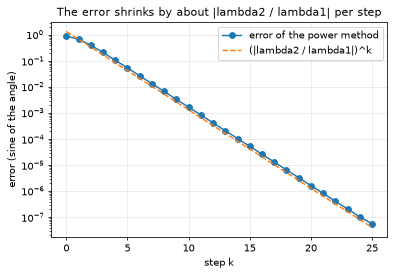

In [13]:
fig, ax = plt.subplots(figsize=(6.2, 4))
steps = np.arange(len(errors))
ax.semilogy(steps, errors + 1e-17, "o-", label="error of the power method")
ax.semilogy(steps, errors[1] * ratio ** (steps - 1), "--", label="(|lambda2 / lambda1|)^k")
ax.set_xlabel("step k"); ax.set_ylabel("error (sine of the angle)")
ax.set_title("The error shrinks by about |lambda2 / lambda1| per step")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 10. Covariance eigenvectors give the axes of the data (PCA)

For centered data, the eigenvectors of the covariance matrix point along the axes of the cloud, and the eigenvalues are the variances along them. We simulate a correlated 2D cloud and draw the axes.

covariance matrix:
 [[4.0672 2.4924]
 [2.4924 2.0091]]
eigenvalues (variances along the axes): [0.3417 5.7346]
standard deviations along the axes    : [0.5845 2.3947]
first principal axis (eigenvector of the largest eigenvalue): [-0.8312 -0.556 ]


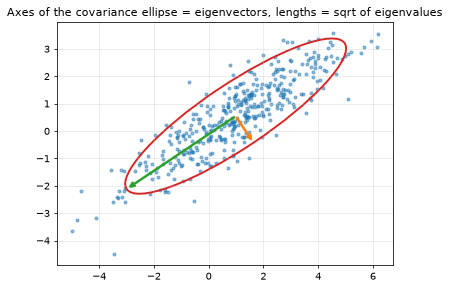

In [14]:
rng = np.random.default_rng(3)
mix = np.array([[2.0, 0.0], [1.2, 0.7]])
points = rng.normal(size=(400, 2)) @ mix.T + np.array([1.0, 0.5])       # a tilted, stretched cloud
mean = points.mean(axis=0)
cov = np.cov(points.T)

w_c, V_c = np.linalg.eigh(cov)                       # ascending order
print("covariance matrix:\n", cov)
print("eigenvalues (variances along the axes):", w_c)
print("standard deviations along the axes    :", np.sqrt(w_c))
print("first principal axis (eigenvector of the largest eigenvalue):", V_c[:, -1])

fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.scatter(*points.T, s=10, alpha=0.5)
angle = np.degrees(np.arctan2(V_c[1, -1], V_c[0, -1]))
ax.add_patch(Ellipse(mean, 2 * 2 * np.sqrt(w_c[-1]), 2 * 2 * np.sqrt(w_c[0]), angle=angle,
                     fill=False, color="C3", lw=2))
for k, color in [(-1, "C2"), (0, "C1")]:
    ax.annotate("", xy=mean + 2 * np.sqrt(w_c[k]) * V_c[:, k], xytext=mean,
                arrowprops=dict(arrowstyle="->", color=color, lw=2.5))
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_title("Axes of the covariance ellipse = eigenvectors, lengths = sqrt of eigenvalues")
plt.show()

## 11. PageRank: the power method on a tiny web

Six invented pages link to each other. The "random surfer" model gives a matrix $M$ whose columns sum to 1. The PageRank scores are the dominant eigenvector, which has eigenvalue 1, and the power method finds it.

In [15]:
pages = ["A", "B", "C", "D", "E", "F"]
links = {"A": ["B", "C"], "B": ["C"], "C": ["A"], "D": ["A", "C", "E"], "E": ["D", "F"], "F": ["D"]}
n = len(pages)
index = {p: i for i, p in enumerate(pages)}

L = np.zeros((n, n))
for src, targets in links.items():
    for dst in targets:
        L[index[dst], index[src]] = 1.0 / len(targets)       # column j: where page j sends its vote

damping = 0.85
M_rank = damping * L + (1 - damping) / n * np.ones((n, n))    # a surfer sometimes jumps to a random page
print("columns sum to 1:", np.allclose(M_rank.sum(axis=0), 1))

rank = np.ones(n) / n
for _ in range(100):
    rank = M_rank @ rank                                      # already sums to 1, no renormalizing needed

w_all, V_all = np.linalg.eig(M_rank)
top = np.argmax(w_all.real)
exact = np.abs(V_all[:, top].real)
exact = exact / exact.sum()
print("dominant eigenvalue:", round(w_all[top].real, 8))
print("power iteration matches the eigenvector:", np.allclose(rank, exact))
for p, score in sorted(zip(pages, rank), key=lambda item: -item[1]):
    print(f"page {p}: {score:.3f}")

columns sum to 1: True
dominant eigenvalue: 1.0
power iteration matches the eigenvector: True
page C: 0.328
page A: 0.328
page B: 0.164
page D: 0.085
page E: 0.049
page F: 0.046


## 12. Gradient descent on a quadratic: eigenvalues set the speed limit

For $f(\mathbf{x}) = \tfrac12\mathbf{x}^\top H\mathbf{x}$ with symmetric positive definite $H$, gradient descent is $\mathbf{x} \leftarrow \mathbf{x} - \alpha H\mathbf{x}$. Along each eigenvector the error is multiplied by $1 - \alpha\lambda$ each step. That gives two facts: the step must satisfy $\alpha < 2/\lambda_{\max}$, and if the eigenvalues are very different, the smallest one converges slowly.

In [16]:
def descend(H, alpha, steps=60, start=(1.0, 1.0)):
    x = np.array(start)
    path = [x.copy()]
    for _ in range(steps):
        x = x - alpha * (H @ x)
        path.append(x.copy())
    return np.array(path)


H_spread = np.diag([1.0, 10.0])          # eigenvalues 1 and 10: spread out, condition number 10
H_even = np.diag([3.0, 4.0])             # eigenvalues 3 and 4: nearly equal

limit = 2 / 10
print("2 / lambda_max for H_spread =", limit)
for alpha in (0.05, 0.18, 0.21):
    final = descend(H_spread, alpha)[-1]
    print(f"alpha = {alpha:.2f}: distance from the minimum after 60 steps = {np.linalg.norm(final):.2e}")

def steps_to_converge(H, alpha, tol=1e-6):
    x = np.array([1.0, 1.0]); count = 0
    while np.linalg.norm(x) > tol and count < 100000:
        x = x - alpha * (H @ x); count += 1
    return count

print("\nsteps to get within 1e-6 using the best fixed step 2/(lmax + lmin):")
for name, H in [("eigenvalues 1 and 10", H_spread), ("eigenvalues 3 and 4 ", H_even)]:
    lmax, lmin = np.linalg.eigvalsh(H)[::-1]
    print(f"  {name}: {steps_to_converge(H, 2 / (lmax + lmin))} steps")

2 / lambda_max for H_spread = 0.2
alpha = 0.05: distance from the minimum after 60 steps = 4.61e-02
alpha = 0.18: distance from the minimum after 60 steps = 6.91e-06
alpha = 0.21: distance from the minimum after 60 steps = 3.04e+02

steps to get within 1e-6 using the best fixed step 2/(lmax + lmin):
  eigenvalues 1 and 10: 71 steps
  eigenvalues 3 and 4 : 8 steps


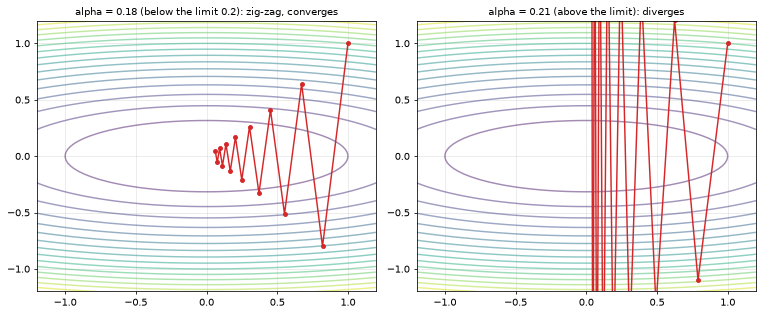

In [17]:
xs, ys = np.meshgrid(np.linspace(-1.2, 1.2, 100), np.linspace(-1.2, 1.2, 100))
fvals = 0.5 * (1.0 * xs ** 2 + 10.0 * ys ** 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, alpha, title in [(axes[0], 0.18, "alpha = 0.18 (below the limit 0.2): zig-zag, converges"),
                         (axes[1], 0.21, "alpha = 0.21 (above the limit): diverges")]:
    path = descend(H_spread, alpha, steps=14)
    ax.contour(xs, ys, fvals, levels=15, alpha=0.5)
    ax.plot(*path.T, "o-", color="C3", ms=4)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Recap and next steps

* An **eigenvector** keeps its direction: $A\mathbf{x} = \lambda\mathbf{x}$. Eigenvalues solve $\det(A - \lambda I) = 0$, add up to the trace, and multiply to the determinant. Eigenvalue 0 means a singular matrix; a rotation has complex eigenvalues.
* With $n$ independent eigenvectors, $A = S\Lambda S^{-1}$ and $A^k = S\Lambda^k S^{-1}$. A defective matrix does not have enough eigenvectors.
* A symmetric matrix has real eigenvalues and orthogonal eigenvectors: $A = Q\Lambda Q^\top$. It is positive definite when all eigenvalues are positive.
* The **power method** multiplies and normalizes, converging to the dominant eigenvector at a rate $|\lambda_2/\lambda_1|^k$. Libraries use the QR algorithm instead (`eig`, `eigh`).
* Eigenvectors appear in PCA (covariance axes), PageRank, and the speed limits of gradient descent.

**Try it yourself:** in section 12, change the second eigenvalue of `H_spread` and see how the limit $2/\lambda_{\max}$ moves. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Linear Transformations](../linear-transformations/README.md).